In [21]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score



In [31]:
data=pd.read_csv("loan_approval_dataset.csv")
print(data)

      loan_id  no_of_dependents      education  self_employed   income_annum  \
0           1                 2       Graduate             No        9600000   
1           2                 0   Not Graduate            Yes        4100000   
2           3                 3       Graduate             No        9100000   
3           4                 3       Graduate             No        8200000   
4           5                 5   Not Graduate            Yes        9800000   
...       ...               ...            ...            ...            ...   
4264     4265                 5       Graduate            Yes        1000000   
4265     4266                 0   Not Graduate            Yes        3300000   
4266     4267                 2   Not Graduate             No        6500000   
4267     4268                 1   Not Graduate             No        4100000   
4268     4269                 1       Graduate             No        9200000   

       loan_amount   loan_term   cibil_

In [32]:
data.dropna(inplace=True)
data.drop_duplicates(inplace=True)
data.describe()

,loan_id,no_of_dependents,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value
count,4269.000000,4269.000000,4.269000e+03,4.269000e+03,4269.000000,4269.000000,4.269000e+03,4.269000e+03,4.269000e+03,4.269000e+03
mean,2135.000000,2.498712,5.059124e+06,1.513345e+07,10.900445,599.936051,7.472617e+06,4.973155e+06,1.512631e+07,4.976692e+06
std,1232.498479,1.695910,2.806840e+06,9.043363e+06,5.709187,172.430401,6.503637e+06,4.388966e+06,9.103754e+06,3.250185e+06
min,1.000000,0.000000,2.000000e+05,3.000000e+05,2.000000,300.000000,-1.000000e+05,0.000000e+00,3.000000e+05,0.000000e+00
25%,1068.000000,1.000000,2.700000e+06,7.700000e+06,6.000000,453.000000,2.200000e+06,1.300000e+06,7.500000e+06,2.300000e+06
50%,2135.000000,3.000000,5.100000e+06,1.450000e+07,10.000000,600.000000,5.600000e+06,3.700000e+06,1.460000e+07,4.600000e+06
75%,3202.000000,4.000000,7.500000e+06,2.150000e+07,16.000000,748.000000,1.130000e+07,7.600000e+06,2.170000e+07,7.100000e+06
max,4269.000000,5.000000,9.900000e+06,3.950000e+07,20.000000,900.000000,2.910000e+07,1.940000e+07,3.920000e+07,1.470000e+07


In [33]:
x1=data[' income_annum']
x1

,income_annum
0,9600000
1,4100000
2,9100000
3,8200000
4,9800000
...,...
4264,1000000
4265,3300000
4266,6500000
4267,4100000


In [34]:
x2=data[' cibil_score']
x2

,cibil_score
0,778
1,417
2,506
3,467
4,382
...,...
4264,317
4265,559
4266,457
4267,780


In [35]:
y=data[' loan_status']
y

,loan_status
0,Approved
1,Rejected
2,Rejected
3,Rejected
4,Rejected
...,...
4264,Rejected
4265,Approved
4266,Rejected
4267,Approved


In [36]:
x=np.column_stack((x1,x2))
x

array([[9600000,     778],
       [4100000,     417],
       [9100000,     506],
       ...,
       [6500000,     457],
       [4100000,     780],
       [9200000,     607]])

In [37]:
y=np.array(y).reshape(-1,1)
y

array([[' Approved'],
       [' Rejected'],
       [' Rejected'],
       ...,
       [' Rejected'],
       [' Approved'],
       [' Approved']], dtype=object)

In [39]:
data[' loan_status']= data[' loan_status'].replace({
    ' Approved': 1,
    ' Rejected': 0
})

In [40]:
print(data[' loan_status'].head())

0    1
1    0
2    0
3    0
4    0
Name:  loan_status, dtype: int64


In [45]:
y=np.array(data[' loan_status'])
moodel=LogisticRegression()
model.fit(x,y)

LinearRegression()

In [46]:
income=int(input("Enter the income"))
cibi=int(input("Enter the cibi"))
inputs=np.column_stack((income,cibi))
print(model.predict(inputs))



Enter the income456600
Enter the cibi456
[0.30821472]


In [47]:
x_lines=np.linspace(1,20,20).reshape(-1,1)
x=data[['hours']]


NameError: name 'y_pre' is not defined

In [48]:
x=data[' cibil_score']
x

,cibil_score
0,778
1,417
2,506
3,467
4,382
...,...
4264,317
4265,559
4266,457
4267,780


In [49]:
print(y)

[1 0 0 ... 0 1 1]


In [52]:
model=LogisticRegression()
model.fit(np.array(x).reshape(-1,1),y)


LogisticRegression()

In [53]:
cibi=int(input("Enter the cibi"))
inputs=np.array(cibi).reshape(-1,1)
print(model.predict(inputs))

Enter the cibi786
[1]


In [56]:
x_lines=np.linspace(1,20,20).reshape(-1,1)
x=data[[' cibil_score']]
y=data[' loan_status']
y_prob=model.predict(x)


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(


R2 Score: 0.6572147237430814


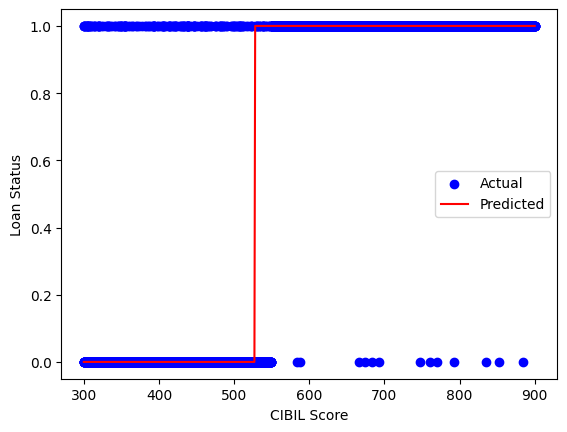

In [60]:
prob = r2_score(y, y_prob)
print("R2 Score:", prob)

plt.scatter(data[' cibil_score'], data[' loan_status'], color='blue', label='Actual')
sorted_indices = np.argsort(data[' cibil_score'])
plt.plot(data[' cibil_score'].iloc[sorted_indices], y_prob[sorted_indices], color='red', label='Predicted')
plt.xlabel('CIBIL Score')
plt.ylabel('Loan Status')
plt.legend()
plt.show()

In [62]:
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier


In [63]:
data=pd.read_csv("trending_videos.csv")
data

,video_id,title,channel_title,published_at,view_count,like_count,comment_count
0,F7dJY0jkpyU,YoungBoy Never Broke Again - Where I Been / Sh...,YoungBoy Never Broke Again,2025-05-03T00:42:17Z,1934714,201321,24214
1,KihGo9jd2As,RYAN GARCIA VS ROLANDO ROMERO | FIGHT HIGHLIGHTS,DAZN Boxing,2025-05-03T02:41:31Z,1833498,19921,5938
2,EeSw7o2NgN0,The Undead War is rising. See how the Witch go...,Clash Royale,2025-05-03T08:00:11Z,1420654,55318,3840
3,u0GCwJcOHxw,Why is Everything So Boring Now?,Kurtis Conner,2025-05-02T19:13:08Z,1384569,107826,10460
4,T2XTfmx7pCw,DDG - what i prefer (Official Music Video),DDGVEVO,2025-05-02T04:00:06Z,866844,76227,8964
5,fZzB6kTXbrU,I was almost in Squid Game.,JaidenAnimations,2025-05-02T17:02:27Z,3112715,239610,10047
6,nt5ZHq4lh1s,Taking my Sister on a Shopping Spree!,Jake Webber,2025-05-02T21:25:30Z,694356,51254,2726
7,3LpzeNLtEhY,10 Days of Chaotic Travel (behind the scenes o...,Kara and Nate,2025-05-03T15:00:04Z,214099,13614,813
8,huywVCJvqn4,I Tested VIRAL Beauty Products you won’t believe,HopeScope,2025-05-03T14:30:21Z,482667,16525,1359
9,-K8jSo03dEk,"planes if they were 10,000 times better",Ice Cream Sandwich,2025-05-03T02:01:54Z,738052,74097,3900


In [65]:
x=data['view_count']
x

,view_count
0,1934714
1,1833498
2,1420654
3,1384569
4,866844
5,3112715
6,694356
7,214099
8,482667
9,738052


In [67]:
data["Popular"] = data["view_count"].apply(
    lambda x: "Popular" if x >= 1000000 else "Not Popular"
)

In [74]:
x = data[["view_count", "like_count"]]
x



,view_count,like_count
0,1934714,201321
1,1833498,19921
2,1420654,55318
3,1384569,107826
4,866844,76227
5,3112715,239610
6,694356,51254
7,214099,13614
8,482667,16525
9,738052,74097


In [73]:
y = data["Popular"]
y

,Popular
0,Popular
1,Popular
2,Popular
3,Popular
4,Not Popular
5,Popular
6,Not Popular
7,Not Popular
8,Not Popular
9,Not Popular


In [75]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.4,random_state=42)


In [76]:
model=KNeighborsClassifier(n_neighbors=3)
model.fit(x_train,y_train)


KNeighborsClassifier(n_neighbors=3)

In [77]:
view=int(input("Enter the view"))
like=int(input("Enter the like"))
inputs=np.array([[view,like]])
print(model.predict(inputs) )

Enter the view67
Enter the like89
['Not Popular']


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but KNeighborsClassifier was fitted with feature names
  warnings.warn(
